# Funktionen mehrerer Veränderlicher IX: Methode der kleinsten Fehlerquadrate

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitt 2.9)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/09_methode_kleinste_fehlerquadrate.ipynb)

**Inhalt**


1. Die Fehlerfunktion $f(a,b)$ als Funktion zweier Veränderlicher
2. Satz 2.9.1: Formeln für $a$ und $b$ (Herleitung mit SymPy)
3. Beispiel 2.9.2: Lernzeit und Punktzahl
4. Interaktiv: eine Gerade von Hand anpassen
5. Ausblick: dieselbe Lösung mit dem Gradientenverfahren


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax

## 1. Die Fehlerfunktion

Gegeben sind Messpunkte $(x_1,y_1),\dots,(x_n,y_n)$. Für eine Gerade $y = ax + b$ misst
$$f(a,b) = \sum_{k=1}^n (y_k - ax_k - b)^2$$
die Summe der quadrierten senkrechten Abstände $d_k = y_k - ax_k - b$. Gesucht ist das Minimum dieser Funktion **zweier** Veränderlicher $a$ und $b$; Abschnitt 2.8.1 liefert das Werkzeug.

## 2. Satz 2.9.1

Sind nicht alle $x_k$ gleich, so hat die beste Gerade mit $\bar x = \frac{1}{n}\sum x_k$, $\bar y = \frac{1}{n}\sum y_k$ und $\langle x,y\rangle = \sum x_ky_k$ die Koeffizienten
$$a = \frac{\langle x,y\rangle - n\bar x\bar y}{\langle x,x\rangle - n\bar x^2},\qquad b = \bar y - a\bar x.$$
**Beweisidee:** $f_b = 0$ liefert $b = \bar y - a\bar x$; eingesetzt in $f_a = 0$ ergibt sich $a$. Die Hesse-Matrix
$$H_f = \begin{pmatrix} 2\langle x,x\rangle & 2n\bar x\\ 2n\bar x & 2n\end{pmatrix}$$
ist positiv definit, denn $\det H_f = 4n\left(\langle x,x\rangle - n\bar x^2\right) = 4n\sum (x_k - \bar x)^2 > 0$ und $f_{aa} > 0$ (Satz 2.8.1.8). Da $f$ quadratisch in $a$ und $b$ ist, ist das Minimum sogar global.

Die folgende Zelle rechnet das für allgemeine $n = 4$ Punkte symbolisch nach.

In [2]:
a, b = sp.symbols('a b', real=True)
n = 4
X_ = sp.symbols(f'x1:{n + 1}', real=True)
Y_ = sp.symbols(f'y1:{n + 1}', real=True)
f_ab = sum((Y_[k] - a*X_[k] - b)**2 for k in range(n))
loes = sp.solve([sp.diff(f_ab, a), sp.diff(f_ab, b)], [a, b], dict=True)[0]
xq, yq = sum(X_)/n, sum(Y_)/n
xy, xx = sum(X_[k]*Y_[k] for k in range(n)), sum(X_[k]**2 for k in range(n))
pruefe('a laut Satz 2.9.1', loes[a] - (xy - n*xq*yq)/(xx - n*xq**2))
pruefe('b = ybar - a xbar', loes[b] - (yq - loes[a]*xq))
H = sp.hessian(f_ab, (a, b))
pruefe('Hesse-Matrix laut Skript', H - sp.Matrix([[2*xx, 2*n*xq], [2*n*xq, 2*n]]))
pruefe('det H = 4n * Summe (x_k - xbar)^2', H.det() - 4*n*sum((X_[k] - xq)**2 for k in range(n)))

Probe a laut Satz 2.9.1: Residuum = 0  -> ok
Probe b = ybar - a xbar: Residuum = 0  -> ok
Probe Hesse-Matrix laut Skript: Residuum = Matrix([[0, 0], [0, 0]])  -> ok
Probe det H = 4n * Summe (x_k - xbar)^2: Residuum = 0  -> ok


## 3. Beispiel 2.9.2

Fünf Studierende notieren Lernzeit $x_k$ (Stunden) und Punktzahl $y_k$: $(2,50)$, $(3,60)$, $(4,65)$, $(5,75)$, $(6,80)$. Mit $n = 5$, $\bar x = 4$, $\bar y = 66$, $\langle x,y\rangle = 1395$, $\langle x,x\rangle = 90$:
$$a = \frac{1395 - 5\cdot 4\cdot 66}{90 - 5\cdot 4^2} = \frac{75}{10} = 7{,}5,\qquad b = 66 - 7{,}5\cdot 4 = 36.$$
Die Ausgleichsgerade ist $y = 7{,}5\,x + 36$: Pro zusätzlicher Lernstunde steigt die Punktzahl im Mittel um 7,5 Punkte.

xbar = 4  ybar = 66  <x,y> = 1395  <x,x> = 90
a = 15/2 = 7.5 ,  b = 36
Probe a = 15/2: Residuum = 0  -> ok
Probe b = 36: Residuum = 0  -> ok
Kontrolle mit numpy.polyfit: [ 7.5 36. ]
minimale Fehlerquadratsumme f(7.5, 36) = 7.5


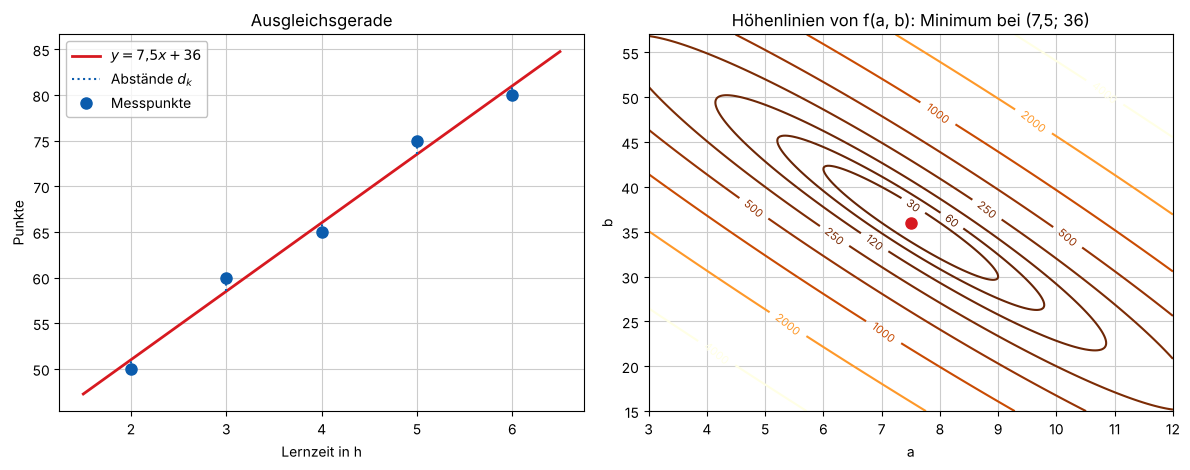

In [3]:
xd = np.array([2, 3, 4, 5, 6]); yd = np.array([50, 60, 65, 75, 80])
xk, yk = [sp.Integer(v) for v in xd], [sp.Integer(v) for v in yd]
n = 5
xq, yq = sum(xk)/n, sum(yk)/n
xy, xx = sum(u*v for u, v in zip(xk, yk)), sum(u**2 for u in xk)
print('xbar =', xq, ' ybar =', yq, ' <x,y> =', xy, ' <x,x> =', xx)
a_w = (xy - n*xq*yq)/(xx - n*xq**2); b_w = yq - a_w*xq
print('a =', a_w, '=', float(a_w), ',  b =', b_w)
pruefe('a = 15/2', a_w - sp.Rational(15, 2)); pruefe('b = 36', b_w - 36)
print('Kontrolle mit numpy.polyfit:', np.polyfit(xd, yd, 1))

f_num = lambda A, B: sum((yv - A*xv - B)**2 for xv, yv in zip(xd, yd))
print('minimale Fehlerquadratsumme f(7.5, 36) =', f_num(7.5, 36))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
xs = np.linspace(1.5, 6.5, 2)
ax1.plot(xs, 7.5*xs + 36, color=ROT, lw=2, label='$y = 7{,}5x + 36$')
ax1.vlines(xd, yd, 7.5*xd + 36, color=BLAU, linestyles=':', label='Abstände $d_k$')
ax1.plot(xd, yd, 'o', color=BLAU, ms=8, label='Messpunkte')
ax1.set(xlabel='Lernzeit in h', ylabel='Punkte', title='Ausgleichsgerade'); ax1.legend()
A, B = np.meshgrid(np.linspace(3, 12, 300), np.linspace(15, 57, 300))
cs = ax2.contour(A, B, f_num(A, B), levels=[30, 60, 120, 250, 500, 1000, 2000, 4000], cmap='YlOrBr_r')
ax2.clabel(cs, fontsize=8)
ax2.plot(7.5, 36, 'o', color=ROT, ms=8)
ax2.set(xlabel='a', ylabel='b', title='Höhenlinien von f(a, b): Minimum bei (7,5; 36)')
plt.tight_layout(); plt.show()

**Interaktiv:** Passen Sie die Gerade von Hand an. Die Quadrate der Abstände sind als Flächen eingezeichnet; ihre Summe ist $f(a,b)$. Das Minimum ist $f(7{,}5;\ 36) = 7{,}5$.

Output()

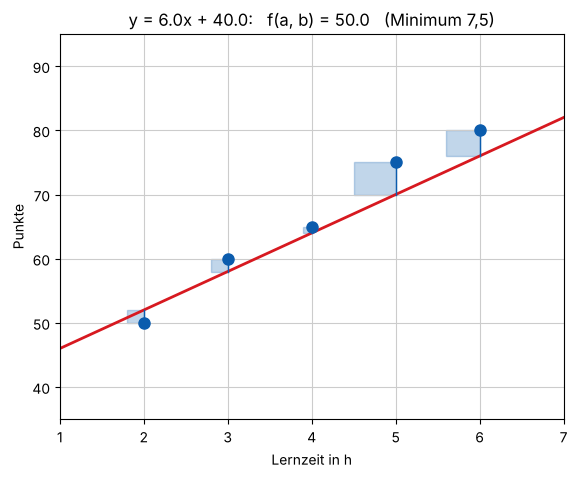

In [4]:
def zeige_gerade(a_=6.0, b_=40.0):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    xs = np.linspace(1, 7, 2)
    ax.plot(xs, a_*xs + b_, color=ROT, lw=2)
    for xv, yv in zip(xd, yd):
        d = yv - (a_*xv + b_)
        ax.add_patch(plt.Rectangle((xv, a_*xv + b_), -abs(d)/10, d, color=BLAU, alpha=0.25))
        ax.plot([xv, xv], [yv, a_*xv + b_], color=BLAU, lw=1)
    ax.plot(xd, yd, 'o', color=BLAU, ms=8)
    ax.set(xlim=(1, 7), ylim=(35, 95), xlabel='Lernzeit in h', ylabel='Punkte',
           title=f'y = {a_:.1f}x + {b_:.1f}:   f(a, b) = {f_num(a_, b_):.1f}   (Minimum 7,5)')
    plt.show()


a_r = widgets.FloatSlider(value=6.0, min=0, max=15, step=0.5, description='a', continuous_update=False)
b_r = widgets.FloatSlider(value=40.0, min=20, max=60, step=1, description='b', continuous_update=False)
display(widgets.HBox([a_r, b_r]), widgets.interactive_output(zeige_gerade, {'a_': a_r, 'b_': b_r}))

# Statische Vorschau für GitHub.
zeige_gerade()

## 5. Ausblick: Gradientenverfahren

Bei der Ausgleichsgeraden kann man das Gleichungssystem $f_a = f_b = 0$ direkt lösen. Bei Modellen mit sehr vielen Parametern (etwa neuronalen Netzen) geht das nicht mehr; dort wird die Fehlerfunktion mit dem **Gradientenverfahren** minimiert (siehe Bemerkung 2.5.6 im Teil 1):
$$\begin{pmatrix} a\\ b\end{pmatrix}_{k+1} = \begin{pmatrix} a\\ b\end{pmatrix}_k - \eta\,\nabla f(a_k, b_k).$$
Hier wird die mittlere Fehlerquadratsumme $\frac{1}{n}f(a,b)$ verwendet (gleiches Minimum, handlichere Schrittweite). Die Höhenlinien sind lange, schmale Ellipsen: Das Verfahren läuft zuerst schnell in das „Tal“ und dann langsam an dessen Boden entlang zum Minimum.

nach 3000 Schritten: a = 7.5 , b = 36.0   (exakt 7,5 und 36)


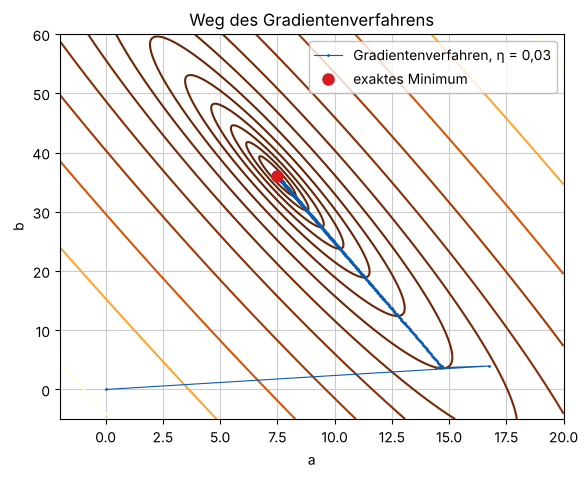

In [5]:
def grad_mse(A, B):
    r = yd - A*xd - B
    return np.array([-2*np.mean(xd*r), -2*np.mean(r)])


p = np.array([0.0, 0.0]); eta = 0.03; weg = [p.copy()]
for k in range(3000):
    p = p - eta*grad_mse(*p)
    weg.append(p.copy())
weg = np.array(weg)
print('nach 3000 Schritten: a =', round(p[0], 4), ', b =', round(p[1], 4), '  (exakt 7,5 und 36)')

fig, ax = plt.subplots(figsize=(6.5, 5))
A, B = np.meshgrid(np.linspace(-2, 20, 300), np.linspace(-5, 60, 300))
ax.contour(A, B, f_num(A, B)/5, levels=np.geomspace(1.5, 5000, 14), cmap='YlOrBr_r')
ax.plot(weg[:, 0], weg[:, 1], '.-', color=BLAU, ms=2, lw=0.8, label='Gradientenverfahren, η = 0,03')
ax.plot(7.5, 36, 'o', color=ROT, ms=8, label='exaktes Minimum')
ax.set(xlabel='a', ylabel='b', title='Weg des Gradientenverfahrens'); ax.legend()
plt.show()